<a href="https://colab.research.google.com/github/KudjoJedidiah/MLWorkshop_by_KNUSTAIClub/blob/main/Assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NAME:ANYOMEDIE JEDIDIAH ELORM

# Process of loading the data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
student_df=pd.read_csv("Student_Performance.csv")


In [ ]:
student_df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [ ]:
print("The number of rows and columns:",student_df.shape)
print("The column types and non-null counts",student_df.info())
print("Missing values per column:",student_df.isnull().sum())
print("Duplicates:",student_df.duplicated().sum())
print("Summary statistics:",student_df.describe())

The number of rows and columns: (10000, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB
The column types and non-null counts None
Missing values per column: Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index      

There are 1000 rows and 6 columns
it can be seen the info that there are no empty rows


*   25% of the students studied for less than 54hrs

*   50% of the students studied for less than 69hrs



   
*   25% of the students perfomace was less than 40

*   50% of the students perfomance were less than 50


*   The average score was 55.2248



*   The largest value for the Hours Studied column was 9
*   The largest value for the Previous Scores column was 99
*   The largest value for the Hours sleep hours column was 9
*   The largest value for the Sample Question Papers Practiced column was 9

*   The largest value for the Performance column was
100








In [ ]:
student_df.duplicated().sum()

np.int64(127)

# Cleaning the **data**

In [ ]:
student_df=student_df.drop_duplicates()

In [ ]:
student_df['Extracurricular Activities']=student_df['Extracurricular Activities'].map({'Yes':1,'No':0})

print(student_df['Extracurricular Activities'].value_counts())
print(student_df.isna().sum().sum(),'Missing values')


Extracurricular Activities
0    4986
1    4887
Name: count, dtype: int64
0 Missing values


As stated earlier there are no missing values in a number column

# Visualizing the data

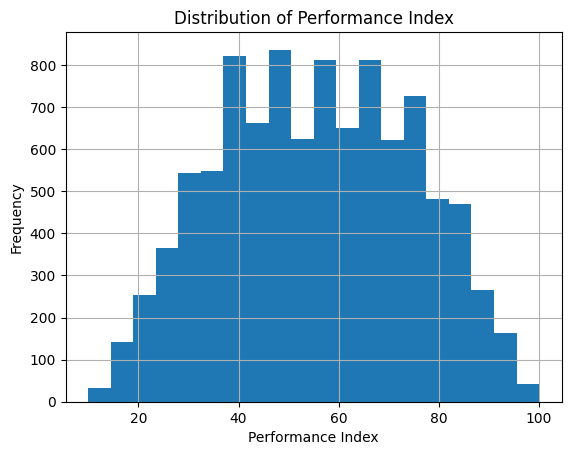

In [ ]:
student_df['Performance Index'].hist(bins=20)
plt.xlabel('Performance Index')
plt.ylabel('Frequency')
plt.title('Distribution of Performance Index')
plt.show()

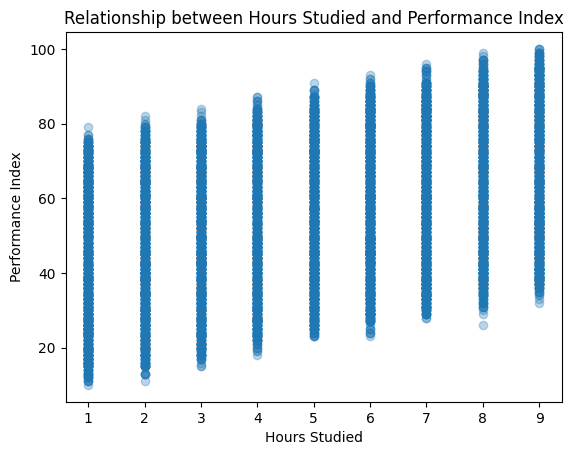

In [ ]:
plt.scatter(student_df['Hours Studied'],student_df['Performance Index'],alpha=0.3)
plt.xlabel('Hours Studied')
plt.ylabel('Performance Index')
plt.title('Relationship between Hours Studied and Performance Index')
plt.show()

The more hours the students studied the better their perfomance index

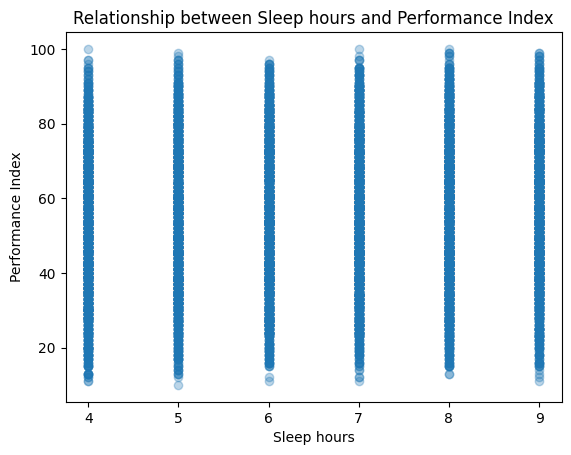

In [ ]:
plt.scatter(student_df['Sleep Hours'],student_df['Performance Index'],alpha=0.3)
plt.xlabel('Sleep hours')
plt.ylabel('Performance Index')
plt.title('Relationship between Sleep hours and Performance Index')
plt.show()

The more the sleep hours the better the student's perfomance index

In [ ]:
print(student_df.corr()['Performance Index'].sort_values(ascending=False))

Performance Index                   1.000000
Previous Scores                     0.915135
Hours Studied                       0.375332
Sleep Hours                         0.050352
Sample Question Papers Practiced    0.043436
Extracurricular Activities          0.026075
Name: Performance Index, dtype: float64


So we can see that there is a positive correlation between the perfomance index and the previous scores.It means that as the previous scores of the students increase their performance index also increases

# Splitting the data

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X=student_df.drop(columns='Performance Index')
y=student_df['Performance Index']

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42)
print(X_train.shape,X_test.shape)

(7898, 5) (1975, 5)


# Training the Model

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error

In [ ]:
model=LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [ ]:
pred=model.predict(X_test)

mae=mean_absolute_error(y_test,pred)
rmse=np.sqrt(mean_squared_error(y_test,pred))
r2=r2_score(y_test,pred)

print(f"Mean Absolute Error:{mae:.2f}")
print(f"RMSE:{rmse:.2f}")
print(f"R-squared:{r2:.2f}")

Mean Absolute Error:1.65
RMSE:2.08
R-squared:0.99




*   On average the prediction is off by 1.65
*



# Comparing with a baseline

In [ ]:
from sklearn.dummy import DummyRegressor

baseline=DummyRegressor(strategy='mean')
baseline.fit(X_train,y_train)

baseline_pred=baseline.predict(X_test)

print("Baseline MAE:",round(mean_absolute_error(y_test,baseline_pred),2))
print("Model MAE:",round(mae,2))

Baseline MAE: 16.25
Model MAE: 1.65


The model's MAE is much smaller than the baseline model so it means the model is better than the baseline

In [ ]:
coefs=pd.Series(model.coef_,index=X.columns)

print(coefs.sort_values(ascending=False).round(2))
print("Intercept:",round(model.intercept_,2))

Hours Studied                       2.85
Previous Scores                     1.02
Extracurricular Activities          0.57
Sleep Hours                         0.47
Sample Question Papers Practiced    0.19
dtype: float64
Intercept: -33.98


# Predicted vs Actual,and a new student

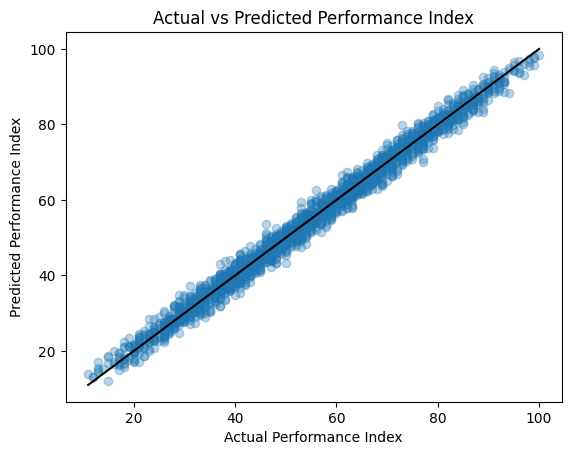

In [ ]:
plt.scatter(y_test,pred,alpha=0.3)
low,high=y_test.min(),y_test.max()
plt.plot([low,high],[low,high],color='black')


plt.xlabel('Actual Performance Index')
plt.ylabel('Predicted Performance Index')
plt.title('Actual vs Predicted Performance Index')
plt.show()

In [ ]:
new_student = pd.DataFrame([{
    "Hours Studied": 6,
    "Previous Scores": 75,
    "Extracurricular Activities": 1,
    "Sleep Hours":7,
    "Sample Question Papers Practiced": 4}])

new_student = new_student[X.columns]
print("Predicted Performance Index:", round(model.predict(new_student)[0], 1))


Predicted Performance Index: 64.1




1.  
*    To predict a student's perfomance index from their study habits and previous results.

*   It is a regression problem.

* The target variable  is a continuous numerical score


2.   
* Dimensions: 10,000 rows and 6 columns.   

* Missing Values: 0 missing values across all columns.   
Duplicates: 127 duplicate rows were identified and removed.


3.
* Target Variable: Performance Index.   
Numerical Features: Hours Studied, Previous Scores, Sleep Hours, and Sample Question Papers Practiced.  
Non-Numerical Feature: Extracurricular Activities (categorical values: "Yes" / "No").
Handling Method: Converted into numerical format using binary encoding


4.   
* Strongest Relationship: Previous Scores has the strongest positive relationship with Performance Index, identified by calculating a correlation matrix where it achieved a Pearson correlation coefficient of 0.92.   

* No, a strong correlation does not prove that. Correlation simply indicates that two variables move together predictably.



5.
* Purpose: Data is split into training and test sets to evaluate how well the trained model generalizes to completely unseen data.


* Testing on the training data causes data leakage and optimistic bias, leading to overfitting where the model memorizes noise in the dataset without learning patterns that generalize to new real world predictions


6.   
* Baseline MAE: 16.25
* Model MAE: 1.65    
* The 14.6-point drop in MAE demonstrates that the features in the trained model capture meaningful structure in the data, significantly outperforming simple average-based guessing.



7.   
* MAE: 1.65   
* RMSE : 2.08   
* R^2  0.99   
* On average, the model's performance score prediction is off by only about 1.65 points from a student's actual score


8.   
* Holding all other factors constant, every additional hour a student studies increases their predicted Performance Index by the coefficient value

* Hours Studied yields the largest single-unit change in performance prediction per unit added compared to a single point increase in Previous Scores

10.   

* Mental health and stress/anxiety levels during exams.

* Socioeconomic background, study environment quality, or access to tutoring resources.

* No, it would not be fair to use this model alone to make high stakes decisions about a student. Statistical algorithms measure correlations across historical data cohorts but miss human factors, individual learning hurdles, and context that holistic evaluation accounts for.




